<a href="https://colab.research.google.com/github/MarquesFernanda/Projeto-IIA/blob/main/Trabalho_IAA_FernandaMarques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Atividade - Classificação Clássica e MLP com PyTorch**

**Observação:** A parte de redes neurais (Exercício 3) deve ser implementada obrigatoriamente com **PyTorch**.

*   **Nome**: Fernanda Marques Pereira
*   **Matrícula**: 222024560

---

# **Classificação de Asteroides Potencialmente Perigosos (NASA - Nearest Earth Objects)**

Nesta atividade, vamos trabalhar com um problema aplicado de **classificação binária** em astrofísica e defesa planetária: prever se um Objeto Próximo à Terra (*Near-Earth Object* — NEO) representa ou não um risco potencial de colisão (**Hazardous**) com base em medições dinâmicas de encontros orbitais e propriedades físicas estimadas.

[NASA - Nearest Earth Objects (Kaggle)](https://www.kaggle.com/datasets/sameepvani/nasa-nearest-earth-objects)

---

## **Contexto**

- O dataset utilizado compila **90.836 registros** de aproximações orbitais à Terra monitoradas pelo *Jet Propulsion Laboratory* (JPL) da NASA, correspondentes a cerca de 27.423 asteroides distintos observados em diferentes épocas.
- O conjunto de dados apresenta desafios fundamentais de ciência de dados e aprendizado de máquina: **repetição do mesmo corpo celeste sob diferentes condições cinemáticas** (velocidade e distância em cada passagem), **variáveis com variância nula**, **risco de vazamento de dados (*data leakage*)**, **colinearidade estrutural**, **distribuições fortemente assimétricas (*heavy-tailed* / lei de potência)** e **desbalanceamento de classes** (Apenas 9,7% de objetos classificados como perigosos).

## **Objetivo**

Desenvolver o pipeline completo de Aprendizado de Máquina Supervisionado — abrangendo limpeza, engenharia de atributos, análise de correlação, reamostragem, escolha da técnica de escalonamento/transformação e comparação entre modelos clássicos (**KNN** e **Regressão Logística**) e redes neurais profundas (**MLP em PyTorch**).

## **Variáveis do Dataset**

Cada observação contém 10 colunas originalmente distribuídas da seguinte forma:

1. **`id`**: Identificador único do asteroide no catálogo da NASA JPL (Variável inteira identificadora).
2. **`name`**: Nome oficial e designação provisória do objeto (Texto identificador).
3. **`est_diameter_min`**: Diâmetro mínimo estimado do asteroide em quilômetros (Variável contínua).
4. **`est_diameter_max`**: Diâmetro máximo estimado do asteroide em quilômetros (Variável contínua).
5. **`relative_velocity`**: Velocidade relativa do objeto em relação à Terra no momento da aproximação, em km/h (Variável contínua).
6. **`miss_distance`**: Distância mínima de passagem (*miss distance*) em relação à Terra, em quilômetros (Variável contínua).
7. **`orbiting_body`**: Corpo celeste de referência da órbita (Texto — constante igual a `"Earth"` em todos os registros).
8. **`sentry_object`**: Indicador booleano informando se o objeto está incluído no sistema automatizado de monitoramento de colisão *Sentry* da NASA (Booleano).
9. **`absolute_magnitude`**: Magnitude absoluta intrínseca ($H$), que mede a luminosidade do corpo celeste (Variável contínua — valores menores indicam objetos maiores e mais brilhantes).

## **Variável de Saída (Target)**

10. **`hazardous`**:
    - **`True` (1)**: *Potentially Hazardous Asteroid* (Asteroide Potencialmente Perigoso).
    - **`False` (0)**: Não perigoso.
  

## **Bibliotecas Permitidas**

Para a execução deste trabalho, é restrito o uso às seguintes bibliotecas do ecossistema Python:

- **Manipulação de Dados e Operações Numéricas:**
  - `pandas`: Carregamento, manipulação tabular, agregação e limpeza de dados.
  - `numpy`: Vetorização, manipulação de arrays e cálculos matemáticos.
- **Visualização de Dados:**
  - `matplotlib` (`matplotlib.pyplot`): Plotagem das curvas de perda e formatação visual geral.
  - `seaborn`: Plotagem do mapa de calor da matriz de correlação e matrizes de confusão.
- **Modelagem Clássica e Pré-processamento (Exercícios 1 e 2):**
  - `scikit-learn` (`sklearn`):
    - `sklearn.model_selection` (`train_test_split`, `GridSearchCV`).
    - `sklearn.preprocessing` (`StandardScaler`, `MinMaxScaler`, `RobustScaler`, `PowerTransformer`, `QuantileTransformer`).
    - `sklearn.neighbors` (`KNeighborsClassifier`).
    - `sklearn.linear_model` (`LogisticRegression`).
    - `sklearn.metrics` (`accuracy_score`, `f1_score`, `confusion_matrix`, `classification_report`).
- **Redes Neurais Artificiais (Exercício 3):**
  - `torch` (`PyTorch`): `torch.nn`, `torch.optim`, `torch.utils.data.TensorDataset` e `torch.utils.data.DataLoader` (o loop de treinamento, validação e early stopping deve ser implementado de forma explícita).
- **Download e Ambiente:**
  - `kagglehub`, `os`, `copy`.

# **Exercício 1 - Preparação dos Dados e Engenharia de Atributos**

1. **Limpeza, Prevenção de Vazamento de Dados (*Data Leakage*) e Engenharia de Features:**
   - Verifique a existência de valores nulos e trate-os caso necessário.
   - Analise criticamente as colunas. Descarte aquelas que são apenas identificadores catalográficos, que possuem **variância zero** (valor constante) ou que configuram **vazamento de dados (*data leakage*)** por já representarem um flag de monitoramento de risco derivado do próprio alvo. Justifique cada remoção.
   - Observe as variáveis `est_diameter_min` e `est_diameter_max`. Como ambas são estimativas derivadas da mesma relação física de magnitude e albedo, avalie a colinearidade entre elas. Seria possível combina-las?
   - Converta a variável alvo `hazardous` para o formato inteiro (`0` e `1`).

2. **Matriz de Correlação e Insights Estatísticos:**
   - Plote a matriz de correlação das variáveis restantes junto à variável alvo `hazardous`.
   - Extraia **pelo menos dois insights estatísticos ou físicos** visíveis na matriz (ex: a relação física entre `absolute_magnitude` e o diâmetro médio).

3. **Análise de Distribuição e Controle de Desbalanceamento:**
   - Verifique a proporção entre as classes `0` e `1` da variável `hazardous`.
   - Para viabilizar o treinamento computacional do `GridSearchCV` no Exercício 2 e evitar o viés severo para a classe majoritária (~90,3% de negativos), aplique **subamostragem aleatória (*Random Under Sampling*)** na classe majoritária (`hazardous == 0`) com `random_state=42`.

**OBS:** Em caso de dúvidas consulte o pdf dado junto a este arquivo.

In [1]:
import pandas as pd
import kagglehub
import os

# Download automático do dataset NASA - Nearest Earth Objects
path = kagglehub.dataset_download("sameepvani/nasa-nearest-earth-objects")
csv_file = os.path.join(path, "neo.csv")

if not os.path.exists(csv_file):
    arquivos = [f for f in os.listdir(path) if f.endswith('.csv')]
    csv_file = os.path.join(path, arquivos[0])

df = pd.read_csv(csv_file)
print(f"Dimensões originais do dataset: {df.shape}")
df.head()

100%|██████████| 6.60M/6.60M [00:01<00:00, 4.80MB/s]

Extracting files...


Dimensões originais do dataset: (90836, 10)


,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False
3,3596030,(2012 BV13),0.096506,0.215794,24764.303138,2.543497e+07,Earth,False,22.20,False
4,3667127,(2014 GE35),0.255009,0.570217,42737.733765,4.627557e+07,Earth,False,20.09,True


In [2]:
# Seu código

df.info()

print(df.isna().sum())

print(df.nunique())

print(df["hazardous"].value_counts())

print(df["hazardous"].value_counts(normalize=True) * 100)

print(df[["est_diameter_min", "est_diameter_max"]].corr())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90836 entries, 0 to 90835
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  90836 non-null  int64  
 1   name                90836 non-null  object 
 2   est_diameter_min    90836 non-null  float64
 3   est_diameter_max    90836 non-null  float64
 4   relative_velocity   90836 non-null  float64
 5   miss_distance       90836 non-null  float64
 6   orbiting_body       90836 non-null  object 
 7   sentry_object       90836 non-null  bool   
 8   absolute_magnitude  90836 non-null  float64
 9   hazardous           90836 non-null  bool   
dtypes: bool(2), float64(5), int64(1), object(2)
memory usage: 5.7+ MB
id                    0
name                  0
est_diameter_min      0
est_diameter_max      0
relative_velocity     0
miss_distance         0
orbiting_body         0
sentry_object         0
absolute_magnitude    0
hazardous       

In [3]:
df_limpo = df.copy()

df_limpo["diameter_mean"] = (
    df_limpo["est_diameter_min"]
    + df_limpo["est_diameter_max"]
) / 2

df_limpo = df_limpo.drop(
    columns=[
        "id",
        "name",
        "orbiting_body",
        "sentry_object",
        "est_diameter_min",
        "est_diameter_max"
    ]
)

df_limpo["hazardous"] = df_limpo["hazardous"].astype(int)

df_limpo.head()

,relative_velocity,miss_distance,absolute_magnitude,hazardous,diameter_mean
0,13569.249224,5.483974e+07,16.73,0,1.938843
1,73588.726663,6.143813e+07,20.00,1,0.430073
2,114258.692129,4.979872e+07,17.83,0,1.168268
3,24764.303138,2.543497e+07,22.20,0,0.156150
4,42737.733765,4.627557e+07,20.09,1,0.412613


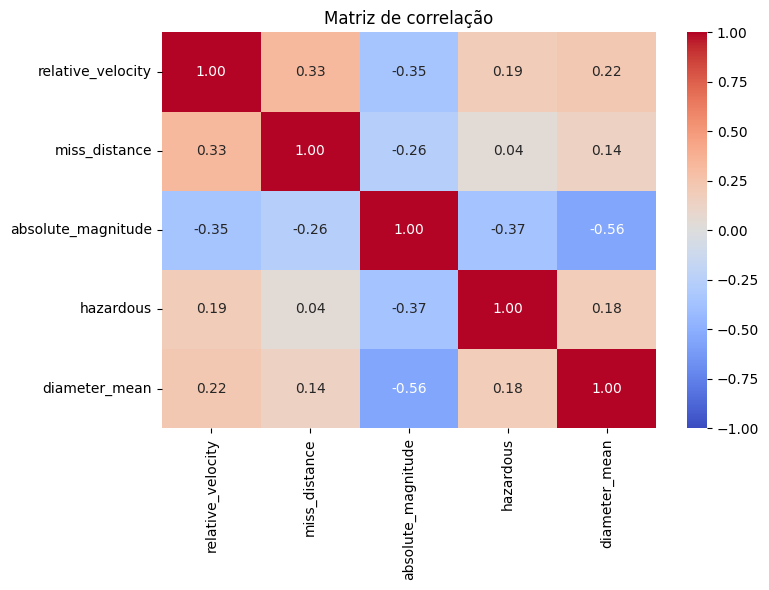

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    df_limpo.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlação")
plt.tight_layout()
plt.show()

In [5]:
perigosos = df_limpo[df_limpo["hazardous"] == 1]

nao_perigosos = df_limpo[df_limpo["hazardous"] == 0]

nao_perigosos_amostra = nao_perigosos.sample(
    n=len(perigosos),
    random_state=42
)

df_balanceado = pd.concat(
    [perigosos, nao_perigosos_amostra],
    ignore_index=True
)

df_balanceado = df_balanceado.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print(df_balanceado.shape)
print(df_balanceado["hazardous"].value_counts())

(17680, 5)
hazardous
1    8840
0    8840
Name: count, dtype: int64


#### Respostas Exercício 1:

1. **Justificativa da Limpeza e Engenharia de Atributos:**

- Não tinha valores nulos.

- Removi `id` e `name` porque identificam apenas os asteroides. Retirei `orbiting_body` e `sentry_object` porque não variam nessa base. O enunciado também pede a retirada de `sentry_object` para evitar vazamento de informação.

- Os dois diâmetros tiveram correlação de 1,0. Por isso usei a média deles para criar `diameter_mean` e removi as duas colunas anteriores.

- Transformei `hazardous` em 0 e 1. Depois sorteei registros da classe não perigosa com `random_state=42` deixando 8.840 de cada classe, totalizando 17.680 registros.

2. **Insights Estatísticos a partir da Matriz de Correlação:**


- A correlação entre magnitude e diâmetro foi −0,56: quanto menor a magnitude, maior tende a ser o diâmetro.

- A correlação entre magnitude e perigo foi −0,37: os registros perigosos tendem a ter magnitude menor.

- A distância teve correlação de 0,04 com o perigo. Mantive essa coluna porque ela pode ajudar quando analisada junto com as outras.


## **Exercício 2 — Comparação de Modelos de Classificação: KNN vs Regressão Logística**

### Objetivo
Treinar e comparar dois modelos de classificação supervisionada usando **scikit-learn**:
- **KNeighborsClassifier** (K-Nearest Neighbors)
- **LogisticRegression** (Regressão Logística)

O foco é aplicar o pré-processamento correto de escala, **encontrar a melhor combinação de hiperparâmetros** para cada modelo e **analisar qual apresenta melhor desempenho** nos conjuntos de treino e teste.

---

### Contexto dos Modelos

- **KNN**: Um algoritmo baseado em instâncias e distâncias geométricas. Para classificar um novo asteroide, ele calcula a distância (Euclidiana ou Manhattan) até os dados de treino e encontra os **K vizinhos mais próximos**, realizando uma votação majoritária ou ponderada sobre esses k vizinhos o algoritmo atribui o rótulo do novo asteroide.
- **Regressão Logística**: Um modelo linear discriminativo que aprende um vetor de **pesos** $w$ para cada variável e aplica a função **sigmoide** ($\sigma(w^T x + b)$) para estimar a probabilidade de o asteroide ser potencialmente perigoso. Pode ser entendido como uma **camada de neurônios única**.

---

### Instruções

1. **Divisão dos Dados e Investigação de Escalonamento**
   - Utilize o dataset limpo e balanceado resultante do Exercício 1.
   - Divida os dados em **80% para treino** e **20% para teste**, de forma **estratificada** (`stratify=y`), usando `train_test_split` com `random_state=42`.
   - **Investigação de Pré-processamento:** Inspecione os histogramas, a assimetria (*skewness*) e as ordens de grandeza das variáveis contínuas (`miss_distance`, `relative_velocity`, `absolute_magnitude` e `diameter_mean`). Pesquise no `scikit-learn.preprocessing` qual técnica de escalonamento ou transformação de distribuição (ex: `StandardScaler`, `MinMaxScaler`, `RobustScaler`, `PowerTransformer`, `QuantileTransformer`) é mais indicada para lidar com variáveis de cauda longa (*heavy-tailed*) e escalas discrepantes.
   - Ajuste o transformador escolhido **exclusivamente no conjunto de treino** (`fit_transform`) e aplique-o no conjunto de teste (`transform`). Justifique sua escolha na seção de respostas.

2. **Treinamento dos Modelos e Busca de Hiperparâmetros**
   - Utilize **GridSearchCV** (`cv=5`, `scoring='f1'`) sobre os dados de treino transformados para encontrar a melhor combinação de parâmetros:
     - **KNN** → `n_neighbors` (ex: 3, 5, 7, 9, 11, 15), `weights` ('uniform', 'distance'), `metric` ('euclidean', 'manhattan').
     - **Regressão Logística** → `C` (ex: 0.01, 0.1, 1, 10, 100), `penalty` ('l1', 'l2'), `solver` ('liblinear').

3. **Execução Final e Avaliação**
   - Treine os dois modelos finais usando os melhores hiperparâmetros encontrados e avalie-os nos conjuntos de **treino** e **teste** usando **Acurácia** e **F1-Score**.

4. **Apresentação e Análise dos Resultados**
   - Preencha a **tabela Markdown** comparativa e responda:
     - a) Qual técnica de escalonamento/transformação você escolheu na etapa 1 e por que ela foi adequada para a distribuição das variáveis deste dataset?
     - b) Qual modelo obteve melhor desempenho no conjunto de teste? Por que a geometria da fronteira de decisão deste problema favorece esse modelo em detrimento do outro?
     - c) Houve **overfitting** em algum dos modelos (ex: influência de `weights='distance'` no KNN)? Justifique comparando as métricas de treino e teste.
     - d) Qual é a diferença fundamental entre como o KNN e a Regressão Logística realizam suas predições, e qual deles se assemelha estruturalmente a um neurônio de uma rede neural?

Dimensões de treino e teste:
(14144, 4) (3536, 4)

Estatísticas das variáveis de treino:
                        mínimo        máximo         média  desvio padrão  \
relative_velocity    1091.0401  2.282422e+05  5.449533e+04   2.726824e+04   
miss_distance       20812.7737  7.479095e+07  3.823395e+07   2.182872e+07   
absolute_magnitude     12.4400  3.295000e+01  2.207840e+01   2.828600e+00   
diameter_mean           0.0011  1.398110e+01  3.300000e-01   4.727000e-01   

                    assimetria  
relative_velocity       0.8457  
miss_distance          -0.0638  
absolute_magnitude      0.4940  
diameter_mean           6.2705  


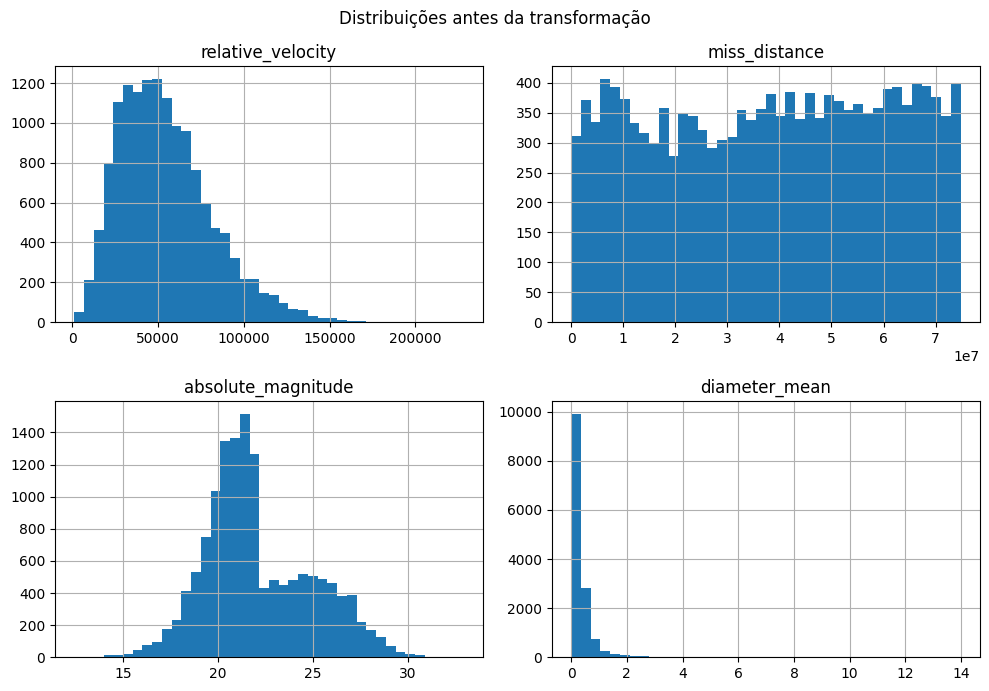


Assimetria antes e depois da transformação:
                     antes  depois
relative_velocity   0.8457 -0.0086
miss_distance      -0.0638 -0.3144
absolute_magnitude  0.4940  0.0018
diameter_mean       6.2705  0.2163


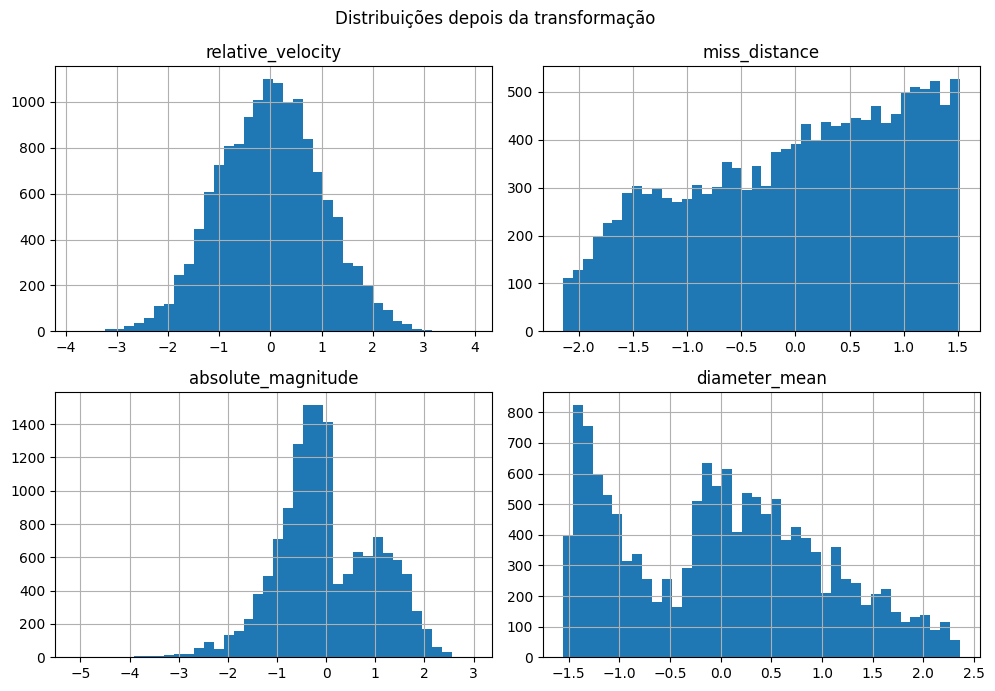


Iniciando a busca do KNN...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Melhores parâmetros do KNN:
{'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'uniform'}
Melhor F1 médio na validação cruzada:
0.8832

Iniciando a busca da Regressão Logística...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Melhores parâmetros da Regressão Logística:
{'C': 0.01, 'penalty': 'l1', 'solver': 'liblinear'}
Melhor F1 médio na validação cruzada:
0.8545

Resultados finais:
             Modelo  Acurácia Treino  F1 Treino  Acurácia Teste  F1 Teste
                KNN           0.8790     0.8907          0.8719    0.8838
Regressão Logística           0.8437     0.8533          0.8462    0.8556

Tabela para copiar na célula de respostas:

| Modelo | Acurácia Treino | F1 Treino | Acurácia Teste | F1 Teste |
|---|---|---|---|---|
| KNN | 0.8790 | 0.8907 | 0.8719 | 0.8838 |
| Regressão Logística | 0.8437 | 0.8533 | 0.8462 | 0.8556 |


In [6]:
# Seu código


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import PowerTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score



X = df_balanceado.drop(columns="hazardous")
y = df_balanceado["hazardous"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Dimensões de treino e teste:")
print(X_train.shape, X_test.shape)



resumo = pd.DataFrame({
    "mínimo": X_train.min(),
    "máximo": X_train.max(),
    "média": X_train.mean(),
    "desvio padrão": X_train.std(),
    "assimetria": X_train.skew()
})

print("\nEstatísticas das variáveis de treino:")
print(resumo.round(4))

X_train.hist(bins=40, figsize=(10, 7))
plt.suptitle("Distribuições antes da transformação")
plt.tight_layout()
plt.show()



transformador = PowerTransformer(
    method="yeo-johnson",
    standardize=True
)

X_train_transformado = transformador.fit_transform(X_train)
X_test_transformado = transformador.transform(X_test)

treino_transformado_df = pd.DataFrame(
    X_train_transformado,
    columns=X_train.columns,
    index=X_train.index
)

print("\nAssimetria antes e depois da transformação:")
print(pd.DataFrame({
    "antes": X_train.skew(),
    "depois": treino_transformado_df.skew()
}).round(4))

treino_transformado_df.hist(bins=40, figsize=(10, 7))
plt.suptitle("Distribuições depois da transformação")
plt.tight_layout()
plt.show()



parametros_knn = {
    "n_neighbors": [3, 5, 7, 9, 11, 15],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

busca_knn = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=parametros_knn,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

print("\nIniciando a busca do KNN...")
busca_knn.fit(X_train_transformado, y_train)

print("Melhores parâmetros do KNN:")
print(busca_knn.best_params_)
print("Melhor F1 médio na validação cruzada:")
print(round(busca_knn.best_score_, 4))



parametros_lr = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"]
}

busca_lr = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=3000,
        random_state=42
    ),
    param_grid=parametros_lr,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

print("\nIniciando a busca da Regressão Logística...")
busca_lr.fit(X_train_transformado, y_train)

print("Melhores parâmetros da Regressão Logística:")
print(busca_lr.best_params_)
print("Melhor F1 médio na validação cruzada:")
print(round(busca_lr.best_score_, 4))



modelos = {
    "KNN": busca_knn.best_estimator_,
    "Regressão Logística": busca_lr.best_estimator_
}

resultados = []

for nome, modelo in modelos.items():
    pred_treino = modelo.predict(X_train_transformado)
    pred_teste = modelo.predict(X_test_transformado)

    resultados.append({
        "Modelo": nome,
        "Acurácia Treino": accuracy_score(y_train, pred_treino),
        "F1 Treino": f1_score(y_train, pred_treino),
        "Acurácia Teste": accuracy_score(y_test, pred_teste),
        "F1 Teste": f1_score(y_test, pred_teste)
    })

resultados_ex2 = pd.DataFrame(resultados)

print("\nResultados finais:")
print(resultados_ex2.round(4).to_string(index=False))



print("\nTabela para copiar na célula de respostas:\n")
print(
    "| Modelo | Acurácia Treino | F1 Treino "
    "| Acurácia Teste | F1 Teste |"
)
print("|---|---|---|---|---|")

for linha in resultados:
    print(
        f"| {linha['Modelo']} "
        f"| {linha['Acurácia Treino']:.4f} "
        f"| {linha['F1 Treino']:.4f} "
        f"| {linha['Acurácia Teste']:.4f} "
        f"| {linha['F1 Teste']:.4f} |"
    )

#### Respostas Exercício 2:

| Modelo | Acurácia Treino | F1 Treino | Acurácia Teste | F1 Teste |
|---|---|---|---|---|
| KNN | 0.8790 | 0.8907 | 0.8719 | 0.8838 |
| Regressão Logística | 0.8437 | 0.8533 | 0.8462 | 0.8556 |

**Melhores parâmetros:**

- KNN: 15 vizinhos, weights='uniform' e metric='manhattan'.
- Regressão Logística: C=0.01, penalty='l1' e solver='liblinear'.

---

**a)**

Usei o powertransformer para colocar as variáveis em escalas parecidas e reduzir a assimetria, principalmente do diâmetro. a assimetria dele caiu de 6,27 para 0,22. o transformador foi ajustado só no treino.

---

**b)**

O KNN foi melhor no teste, com F1 de 0,8838. ele usa os exemplos mais próximos e consegue separar as classes de formas mais flexíveis que a Regressão Logística.

---

**c)**

não houve sinal forte de overfitting pois os resultados de treino e teste ficaram próximos nos dois modelos. no KNN, o F1 foi 0,8907 no treino e 0,8838 no teste.

A melhor configuração usou pesos iguais para os vizinhos. Com weights='distance', os vizinhos mais próximos teriam mais influência, o que pode aumentar a chance de memorizar o treino.

---

**d)**

O KNN prevê olhando os vizinhos mais próximos. A Regressão Logística aprende pesos para calcular a chance de cada classe. Ela funciona como um neurônio com ativação sigmoide, sem camadas ocultas.

# **Exercício 3 - Construção e Exploração de MLP com PyTorch**

Neste exercício, você vai construir, treinar e comparar diferentes arquiteturas de MLP (Multi-Layer Perceptron) para resolver o mesmo problema de classificação dos exercícios anteriores.

**O uso de PyTorch é obrigatório para resolução deste exercício.**

---

### Instruções

1. **Divisão e Padronização dos dados**
   - A partir do dataset tratado no Exercício 1, faça a divisão estratificada dos dados:
     - 70% para treino
     - 15% para validação
     - 15% para teste
   - Converta os arrays resultantes para tensores do PyTorch (`torch.float32`) e estruture os `TensorDataset` e `DataLoader`.

2. **Treinamento de múltiplas arquiteturas**
   - Treine **pelo menos 5 arquiteturas diferentes** de MLP, variando:
     - Número de camadas ocultas (1, 2, 3, 4, 5 camadas)
     - Número de neurônios por camada (ex: 16, 32, 64, 128)
     - Função de ativação (ex: ReLU, Tanh, Sigmoid)
   - Para cada arquitetura, utilize o mesmo otimizador e função de perda.

3. **Implementação de Early Stopping**
   - Implemente **early stopping** com base na loss de validação.
   - O treinamento deve parar automaticamente quando a loss de validação **não melhorar** por um número definido de épocas consecutivas (patience).
   - Dica: guarde os pesos do melhor modelo durante o treino.

4. **Avaliação de cada arquitetura**
   - Para **cada** arquitetura treinada, apresente:
     - Acurácia no conjunto de teste
     - Matriz de confusão
     - Relatório de classificação

5. **Tabela comparativa**
   - Monte uma tabela Markdown comparando as arquiteturas (veja o modelo na seção de Respostas abaixo).

6. **Curvas de aprendizado**
   - Plote a **loss de treino** e a **loss de validação** ao longo das épocas para cada arquitetura.
   - Identifique visualmente em qual ponto o early stopping atuou.

7. **Análise dos resultados**
   - Responda:
     - a) O early stopping foi ativado em todas as arquiteturas? Em que época, em média? O que isso indica sobre o treinamento?
     - b) Qual arquitetura obteve a melhor generalização (melhor desempenho no teste)? Por que?
     - c) Compare as curvas de aprendizado. Houve sinais de overfitting em alguma arquitetura? Como o early stopping ajudou (ou não) a mitigar isso?
     - d) A Regressão Logística do Exercício 2 pode ser vista como um caso especial de MLP (sem camadas ocultas). Comparando os resultados, as camadas adicionais trouxeram benefício significativo para este dataset? As camadas adicionais no MLP melhoraram os resultados?

## Respostas Exercício 3

| Arquitetura | Camadas | Neurônios | Ativação | Época Parada | Acurácia (Teste) | F1-Score (Teste) |
|---|---|---|---|---|---|---|
| MLP 1 | 1 | [32] | ReLU | 110 | 0.8801 | 0.8918 |
| MLP 2 | 2 | [64, 32] | ReLU | 33 | 0.8812 | 0.8928 |
| MLP 3 | 3 | [128, 64, 32] | Tanh | 44 | 0.8801 | 0.8918 |
| MLP 4 | 4 | [128, 64, 32, 16] | ReLU | 49 | 0.8797 | 0.8913 |
| MLP 5 | 5 | [128, 64, 32, 16, 8] | Sigmoid | 86 | 0.8759 | 0.8887 |

**a)** Sim, as cinco redes pararam pelo early stopping. A média foi de 64,4 épocas. Elas pararam porque a perda de validação deixou de melhorar o suficiente.

**b)** A MLP 2 foi a melhor no teste, com acurácia de 0,8812 e F1 de 0,8928. Ela também teve a menor perda de validação. Duas camadas foram suficientes; colocar mais camadas não ajudou.

**c)** Não apareceu sinal forte de overfitting. As perdas de treino e validação caíram e depois ficaram próximas e estáveis. O early stopping encerrou o treino e recuperou os pesos da melhor época.

**d)** As redes tiveram F1 maior que a Regressão Logística: 0,8928 contra 0,8556. Isso indica que as camadas ocultas podem ter ajudado, mas os testes usaram divisões diferentes. Entre as redes, aumentar o número de camadas não melhorou o resultado.

# Modelo de tabela:

| Arquitetura | Camadas | Neurônios          | Ativação | Época Parada | Acurácia (Teste) | F1-Score (Teste) |
|:------------|:--------|:-------------------|:---------|:-------------|:----------------:|:----------------:|
| MLP 1       | 1       | [32]               | ReLU     | --           | 0.0000           | 0.0000           |
| MLP 2       | 2       | [64, 32]           | ReLU     | --           | 0.0000           | 0.0000           |
| MLP 3       | 3       | [128, 64, 32]      | ReLU/Tanh| --           | 0.0000           | 0.0000           |
| MLP 4       | 4       | [128, 64, 32, 16]  | ReLU/Tanh| --           | 0.0000           | 0.0000           |

In [9]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

def avaliar_modelo(y_true_test, y_pred_test, titulo="Modelo"):
    # --- Acurácia
    acc_test = accuracy_score(y_true_test, y_pred_test)
    print(f"Acurácia no conjunto de teste ({titulo}): {acc_test:.4f}")

    # --- Matriz de confusão
    cm = confusion_matrix(y_true_test, y_pred_test)
    plt.figure(figsize=(4, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Matriz de Confusão - {titulo}')
    plt.xlabel('Classe Predita')
    plt.ylabel('Classe Real')
    plt.tight_layout()
    plt.show()

    # --- Relatório de classificação
    print("\nRelatório de Classificação:")
    print(classification_report(y_true_test, y_pred_test, digits=4, zero_division=1))


Dispositivo: cpu
Treino: (12376, 4)
Validação: (2652, 4)
Teste: (2652, 4)

Treinando MLP 1
Neurônios: [32] | Ativação: ReLU
Época 1: loss treino=0.5608, loss validação=0.4770
Época 20: loss treino=0.3069, loss validação=0.2969
Época 40: loss treino=0.2985, loss validação=0.2908
Época 60: loss treino=0.2962, loss validação=0.2896
Época 80: loss treino=0.2948, loss validação=0.2891
Época 100: loss treino=0.2939, loss validação=0.2886
Early stopping na época 110.

Acurácia de teste: 0.8801
F1 de teste: 0.8918

Relatório de classificação:
              precision    recall  f1-score   support

Não perigoso     0.9846    0.7722    0.8656      1326
    Perigoso     0.8127    0.9879    0.8918      1326

    accuracy                         0.8801      2652
   macro avg     0.8986    0.8801    0.8787      2652
weighted avg     0.8986    0.8801    0.8787      2652



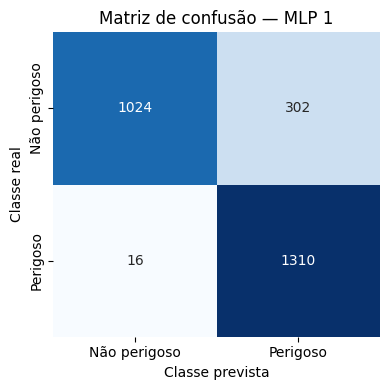

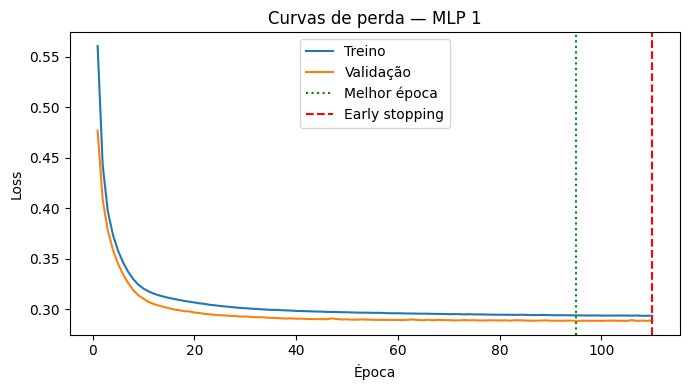


Treinando MLP 2
Neurônios: [64, 32] | Ativação: ReLU
Época 1: loss treino=0.4750, loss validação=0.3536
Época 20: loss treino=0.2948, loss validação=0.2881
Early stopping na época 33.

Acurácia de teste: 0.8812
F1 de teste: 0.8928

Relatório de classificação:
              precision    recall  f1-score   support

Não perigoso     0.9865    0.7730    0.8668      1326
    Perigoso     0.8134    0.9894    0.8928      1326

    accuracy                         0.8812      2652
   macro avg     0.9000    0.8812    0.8798      2652
weighted avg     0.9000    0.8812    0.8798      2652



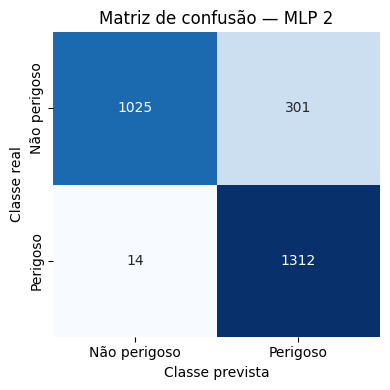

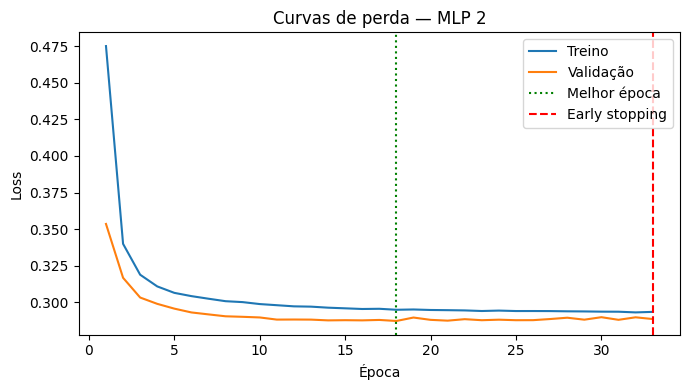


Treinando MLP 3
Neurônios: [128, 64, 32] | Ativação: Tanh
Época 1: loss treino=0.4126, loss validação=0.3413
Época 20: loss treino=0.2996, loss validação=0.2934
Época 40: loss treino=0.2941, loss validação=0.2886
Early stopping na época 44.

Acurácia de teste: 0.8801
F1 de teste: 0.8918

Relatório de classificação:
              precision    recall  f1-score   support

Não perigoso     0.9855    0.7715    0.8655      1326
    Perigoso     0.8123    0.9887    0.8918      1326

    accuracy                         0.8801      2652
   macro avg     0.8989    0.8801    0.8787      2652
weighted avg     0.8989    0.8801    0.8787      2652



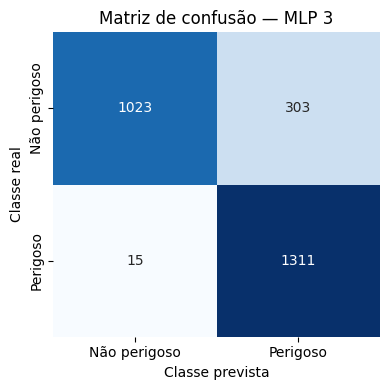

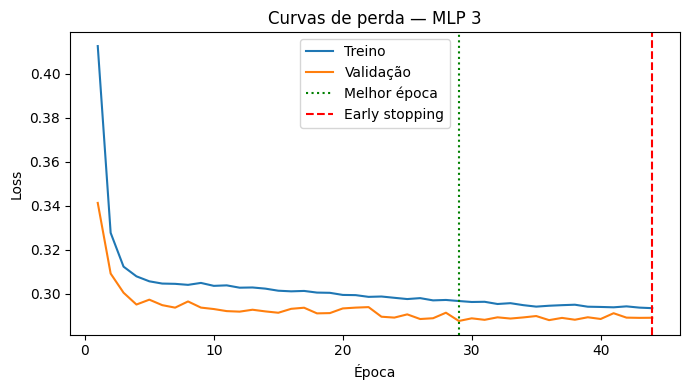


Treinando MLP 4
Neurônios: [128, 64, 32, 16] | Ativação: ReLU
Época 1: loss treino=0.4309, loss validação=0.3127
Época 20: loss treino=0.2936, loss validação=0.2920
Época 40: loss treino=0.2917, loss validação=0.2883
Early stopping na época 49.

Acurácia de teste: 0.8797
F1 de teste: 0.8913

Relatório de classificação:
              precision    recall  f1-score   support

Não perigoso     0.9827    0.7730    0.8653      1326
    Perigoso     0.8129    0.9864    0.8913      1326

    accuracy                         0.8797      2652
   macro avg     0.8978    0.8797    0.8783      2652
weighted avg     0.8978    0.8797    0.8783      2652



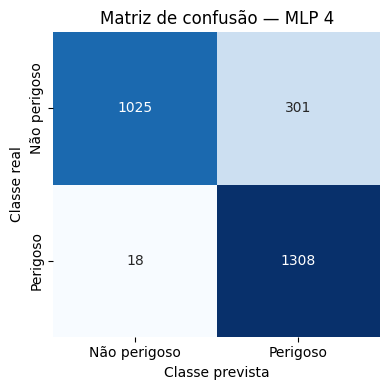

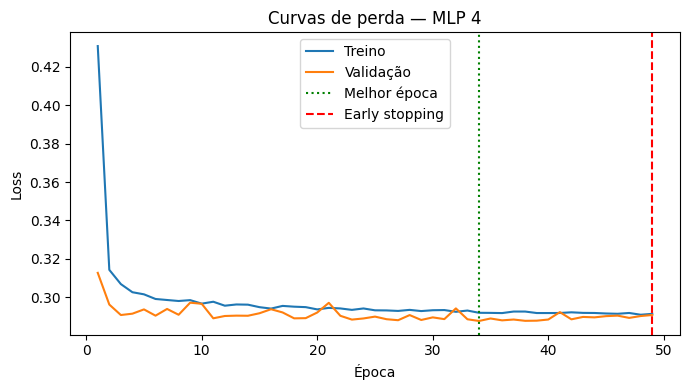


Treinando MLP 5
Neurônios: [128, 64, 32, 16, 8] | Ativação: Sigmoid
Época 1: loss treino=0.6872, loss validação=0.6575
Época 20: loss treino=0.3231, loss validação=0.3120
Época 40: loss treino=0.3207, loss validação=0.3091
Época 60: loss treino=0.3193, loss validação=0.3082
Época 80: loss treino=0.3187, loss validação=0.3085
Early stopping na época 86.

Acurácia de teste: 0.8759
F1 de teste: 0.8887

Relatório de classificação:
              precision    recall  f1-score   support

Não perigoso     0.9882    0.7609    0.8598      1326
    Perigoso     0.8056    0.9910    0.8887      1326

    accuracy                         0.8759      2652
   macro avg     0.8969    0.8759    0.8743      2652
weighted avg     0.8969    0.8759    0.8743      2652



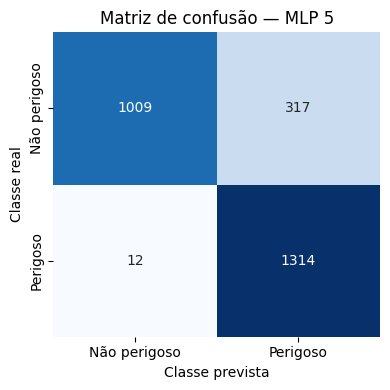

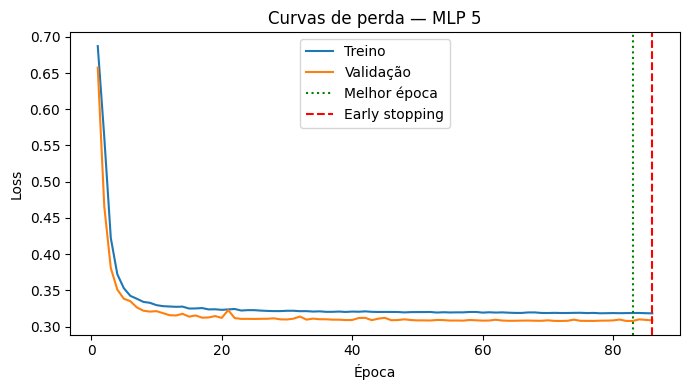


RESUMO FINAL:
Arquitetura  Camadas            Neurônios Ativação  Época parada  Melhor época  Early stopping  Loss validação  F1 validação  Acurácia teste  F1 teste
      MLP 1        1                 [32]     ReLU           110            95            True          0.2886        0.8927          0.8801    0.8918
      MLP 2        2             [64, 32]     ReLU            33            18            True          0.2873        0.8931          0.8812    0.8928
      MLP 3        3        [128, 64, 32]     Tanh            44            29            True          0.2877        0.8931          0.8801    0.8918
      MLP 4        4    [128, 64, 32, 16]     ReLU            49            34            True          0.2876        0.8933          0.8797    0.8913
      MLP 5        5 [128, 64, 32, 16, 8]  Sigmoid            86            83            True          0.3077        0.8910          0.8759    0.8887

Arquiteturas com early stopping: 5 de 5
Época média de parada entre as que par

In [10]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

np.random.seed(42)
torch.manual_seed(42)

dispositivo = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", dispositivo)

X_mlp = df_balanceado.drop(columns="hazardous")
y_mlp = df_balanceado["hazardous"]

X_treino_mlp, X_restante, y_treino_mlp, y_restante = train_test_split(
    X_mlp,
    y_mlp,
    test_size=0.30,
    stratify=y_mlp,
    random_state=42
)

X_val_mlp, X_teste_mlp, y_val_mlp, y_teste_mlp = train_test_split(
    X_restante,
    y_restante,
    test_size=0.50,
    stratify=y_restante,
    random_state=42
)

print("Treino:", X_treino_mlp.shape)
print("Validação:", X_val_mlp.shape)
print("Teste:", X_teste_mlp.shape)

transformador_mlp = PowerTransformer(
    method="yeo-johnson",
    standardize=True
)

X_treino_mlp_t = transformador_mlp.fit_transform(X_treino_mlp)
X_val_mlp_t = transformador_mlp.transform(X_val_mlp)
X_teste_mlp_t = transformador_mlp.transform(X_teste_mlp)

dataset_treino = TensorDataset(
    torch.tensor(X_treino_mlp_t, dtype=torch.float32),
    torch.tensor(
        y_treino_mlp.to_numpy(),
        dtype=torch.float32
    ).reshape(-1, 1)
)

dataset_val = TensorDataset(
    torch.tensor(X_val_mlp_t, dtype=torch.float32),
    torch.tensor(
        y_val_mlp.to_numpy(),
        dtype=torch.float32
    ).reshape(-1, 1)
)

dataset_teste = TensorDataset(
    torch.tensor(X_teste_mlp_t, dtype=torch.float32),
    torch.tensor(
        y_teste_mlp.to_numpy(),
        dtype=torch.float32
    ).reshape(-1, 1)
)

loader_val = DataLoader(
    dataset_val,
    batch_size=256,
    shuffle=False
)

loader_teste = DataLoader(
    dataset_teste,
    batch_size=256,
    shuffle=False
)

arquiteturas = [
    {
        "nome": "MLP 1",
        "neuronios": [32],
        "ativacao": "ReLU"
    },
    {
        "nome": "MLP 2",
        "neuronios": [64, 32],
        "ativacao": "ReLU"
    },
    {
        "nome": "MLP 3",
        "neuronios": [128, 64, 32],
        "ativacao": "Tanh"
    },
    {
        "nome": "MLP 4",
        "neuronios": [128, 64, 32, 16],
        "ativacao": "ReLU"
    },
    {
        "nome": "MLP 5",
        "neuronios": [128, 64, 32, 16, 8],
        "ativacao": "Sigmoid"
    }
]


def construir_mlp(n_entradas, neuronios, ativacao):
    tipos_ativacao = {
        "ReLU": nn.ReLU,
        "Tanh": nn.Tanh,
        "Sigmoid": nn.Sigmoid
    }

    camadas = []
    tamanho_anterior = n_entradas

    for quantidade in neuronios:
        camadas.append(nn.Linear(tamanho_anterior, quantidade))
        camadas.append(tipos_ativacao[ativacao]())
        tamanho_anterior = quantidade

    camadas.append(nn.Linear(tamanho_anterior, 1))

    return nn.Sequential(*camadas)


def treinar_mlp(
    modelo,
    loader_treino,
    loader_validacao,
    max_epocas=200,
    patience=15,
    min_delta=0.0001
):
    criterio = nn.BCEWithLogitsLoss()
    otimizador = torch.optim.Adam(
        modelo.parameters(),
        lr=0.001
    )

    historico = {"treino": [], "validacao": []}

    melhor_loss = float("inf")
    melhor_referencia = float("inf")
    melhores_pesos = copy.deepcopy(modelo.state_dict())
    melhor_epoca = 0
    sem_melhora = 0
    parou_cedo = False

    for epoca in range(1, max_epocas + 1):
        modelo.train()
        soma_loss_treino = 0.0

        for entradas, alvos in loader_treino:
            entradas = entradas.to(dispositivo)
            alvos = alvos.to(dispositivo)

            otimizador.zero_grad()
            logits = modelo(entradas)
            loss = criterio(logits, alvos)
            loss.backward()
            otimizador.step()

            soma_loss_treino += loss.item() * entradas.size(0)

        loss_treino = (
            soma_loss_treino / len(loader_treino.dataset)
        )

        modelo.eval()
        soma_loss_val = 0.0

        with torch.no_grad():
            for entradas, alvos in loader_validacao:
                entradas = entradas.to(dispositivo)
                alvos = alvos.to(dispositivo)

                logits = modelo(entradas)
                loss = criterio(logits, alvos)

                soma_loss_val += loss.item() * entradas.size(0)

        loss_val = (
            soma_loss_val / len(loader_validacao.dataset)
        )

        historico["treino"].append(loss_treino)
        historico["validacao"].append(loss_val)

        if loss_val < melhor_loss:
            melhor_loss = loss_val
            melhor_epoca = epoca
            melhores_pesos = copy.deepcopy(modelo.state_dict())

        if loss_val < melhor_referencia - min_delta:
            melhor_referencia = loss_val
            sem_melhora = 0
        else:
            sem_melhora += 1

        if epoca == 1 or epoca % 20 == 0:
            print(
                f"Época {epoca}: "
                f"loss treino={loss_treino:.4f}, "
                f"loss validação={loss_val:.4f}"
            )

        if sem_melhora >= patience:
            parou_cedo = True
            print(f"Early stopping na época {epoca}.")
            break

    modelo.load_state_dict(melhores_pesos)

    return {
        "historico": historico,
        "epoca_parada": epoca,
        "melhor_epoca": melhor_epoca,
        "melhor_loss_val": melhor_loss,
        "early_stopping": parou_cedo
    }


def prever_mlp(modelo, loader):
    modelo.eval()
    previsoes = []

    with torch.no_grad():
        for entradas, _ in loader:
            entradas = entradas.to(dispositivo)

            probabilidades = torch.sigmoid(modelo(entradas))
            classes = (probabilidades >= 0.5).int()

            previsoes.append(
                classes.cpu().numpy().reshape(-1)
            )

    return np.concatenate(previsoes)


resultados_mlp = []
historicos_mlp = {}
modelos_mlp = {}

for config in arquiteturas:
    print(f"\nTreinando {config['nome']}")
    print(
        "Neurônios:", config["neuronios"],
        "| Ativação:", config["ativacao"]
    )

    torch.manual_seed(42)
    gerador = torch.Generator().manual_seed(42)

    loader_treino = DataLoader(
        dataset_treino,
        batch_size=128,
        shuffle=True,
        generator=gerador
    )

    modelo = construir_mlp(
        n_entradas=X_treino_mlp.shape[1],
        neuronios=config["neuronios"],
        ativacao=config["ativacao"]
    ).to(dispositivo)

    treinamento = treinar_mlp(
        modelo,
        loader_treino,
        loader_val
    )

    pred_val = prever_mlp(modelo, loader_val)
    pred_teste = prever_mlp(modelo, loader_teste)

    acc_teste = accuracy_score(y_teste_mlp, pred_teste)

    f1_teste = f1_score(
        y_teste_mlp,
        pred_teste,
        zero_division=0
    )

    f1_val = f1_score(
        y_val_mlp,
        pred_val,
        zero_division=0
    )

    resultados_mlp.append({
        "Arquitetura": config["nome"],
        "Camadas": len(config["neuronios"]),
        "Neurônios": str(config["neuronios"]),
        "Ativação": config["ativacao"],
        "Época parada": treinamento["epoca_parada"],
        "Melhor época": treinamento["melhor_epoca"],
        "Early stopping": treinamento["early_stopping"],
        "Loss validação": treinamento["melhor_loss_val"],
        "F1 validação": f1_val,
        "Acurácia teste": acc_teste,
        "F1 teste": f1_teste
    })

    historicos_mlp[config["nome"]] = treinamento
    modelos_mlp[config["nome"]] = modelo

    print(f"\nAcurácia de teste: {acc_teste:.4f}")
    print(f"F1 de teste: {f1_teste:.4f}")

    print("\nRelatório de classificação:")
    print(classification_report(
        y_teste_mlp,
        pred_teste,
        labels=[0, 1],
        target_names=["Não perigoso", "Perigoso"],
        digits=4,
        zero_division=0
    ))

    plt.figure(figsize=(4, 4))

    sns.heatmap(
        confusion_matrix(
            y_teste_mlp,
            pred_teste,
            labels=[0, 1]
        ),
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Não perigoso", "Perigoso"],
        yticklabels=["Não perigoso", "Perigoso"]
    )

    plt.title(f"Matriz de confusão — {config['nome']}")
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe real")
    plt.tight_layout()
    plt.show()

    historico = treinamento["historico"]
    epocas = range(1, treinamento["epoca_parada"] + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(epocas, historico["treino"], label="Treino")
    plt.plot(epocas, historico["validacao"], label="Validação")

    plt.axvline(
        treinamento["melhor_epoca"],
        color="green",
        linestyle=":",
        label="Melhor época"
    )

    if treinamento["early_stopping"]:
        plt.axvline(
            treinamento["epoca_parada"],
            color="red",
            linestyle="--",
            label="Early stopping"
        )

    plt.title(f"Curvas de perda — {config['nome']}")
    plt.xlabel("Época")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

tabela_mlp = pd.DataFrame(resultados_mlp)

print("\nRESUMO FINAL:")
print(tabela_mlp.round(4).to_string(index=False))

paradas = tabela_mlp[tabela_mlp["Early stopping"]]

print(
    "\nArquiteturas com early stopping:",
    len(paradas),
    "de",
    len(tabela_mlp)
)

if not paradas.empty:
    print(
        "Época média de parada entre as que pararam:",
        round(paradas["Época parada"].mean(), 2)
    )

melhor_por_validacao = tabela_mlp.loc[
    tabela_mlp["Loss validação"].idxmin(),
    "Arquitetura"
]

print(
    "Arquitetura escolhida pela menor loss de validação:",
    melhor_por_validacao
)

print("\nTABELA PARA COPIAR NAS RESPOSTAS:\n")

print(
    "| Arquitetura | Camadas | Neurônios | Ativação "
    "| Época Parada | Acurácia (Teste) | F1-Score (Teste) |"
)

print("|---|---|---|---|---|---|---|")

for linha in resultados_mlp:
    print(
        f"| {linha['Arquitetura']} "
        f"| {linha['Camadas']} "
        f"| {linha['Neurônios']} "
        f"| {linha['Ativação']} "
        f"| {linha['Época parada']} "
        f"| {linha['Acurácia teste']:.4f} "
        f"| {linha['F1 teste']:.4f} |"
    )

## QA

1. **No dataset bruto da NASA/JPL, as classes são extremamente desbalanceadas (~99,78% não perigosos e ~0,22% potencialmente perigosos) e, mesmo após o undersampling proposto no Exercício 1, a classe positiva permanece minoritária. Como esse desbalanceamento afeta a interpretação da acurácia? Que métricas alternativas e modificações na função de perda (ex: na `BCEWithLogitsLoss` do PyTorch) seriam mais adequadas caso treinássemos o modelo na proporção original?**

2. **Durante o pré-processamento, removemos colunas como `id`, `spkid` e `full_name`, além de ajustarmos o `StandardScaler` apenas no conjunto de treino antes de aplicá-lo na validação e no teste. O que é o fenômeno de *Data Leakage* (vazamento de dados) e por que ajustar o escalonador no dataset inteiro antes do `train_test_split` invalida a avaliação do modelo?**

3. **Um modelo de classificação apresenta acurácia e F1-Score de 100% no conjunto de treino, mas apenas 62% de F1-Score no conjunto de teste. Que fenômeno está ocorrendo? Cite pelo menos três técnicas de regularização (tanto em modelos clássicos quanto em redes neurais PyTorch) que poderiam ser usadas para mitigar esse problema.**

4. **Durante o treinamento de uma rede neural profunda (especialmente ao usar funções de ativação saturáveis como `Sigmoid` ou `Tanh`), as camadas iniciais deixam de atualizar seus pesos, apresentando gradientes próximos de zero. Que fenômeno está ocorrendo e quais estratégias arquiteturais ou de inicialização podem ser aplicadas para solucioná-lo?**

5. **Considere a aplicação prática deste sistema em um observatório astronômico que precisa processar milhões de novos registros do catálogo JPL. Compare o funcionamento do KNN com o de uma rede neural MLP considerando custo computacional de treinamento, consumo de memória RAM, impacto da alta dimensionalidade (*Curse of Dimensionality*) e latência de inferência em produção.**

### Respostas QA

1. A acurácia pode esconder erros na classe perigosa. Usaria recall, precisão, F1 e matriz de confusão. Na BCEWithLogitsLoss usaria pos_weight = negativos/positivos do treino para dar mais peso a classe perigosa. Nesta base as classes eram 90,3% e 9,7%, após o balanceamento, ficaram 50% e 50%.

2. Data leakage é usar no treino informações que deveriam ficar de fora. Ajustar o escalonador antes da divisão usa informações do teste e compromete a avaliação. Ele deve ser ajustado só no treino.

3. Overfitting. Para reduzir: regularização L1 ou L2 nos modelos clássicos, dropout nas redes e early stopping.

4. Desaparecimento de gradientes. Podemos usar ReLU, inicialização He para ReLU ou Xavier para Tanh e conexões residuais.

5. O KNN tem treino barato, mas guarda os exemplos na RAM e pode demorar para prever. Com muitas variáveis as distâncias ficam menos úteis. A MLP custa mais para treinar mas guarda os pesos e costuma prever mais rápido. Muitas variáveis também aumentam seu custo e a necessidade de dados.